<!-- phase:1 -->
# StreamLoop churn classifier: systematic hyperparameter tuning

The first version of the churn model was trained with default settings and called done. This notebook answers the tech lead's follow-up: **is that model actually good, and how do we know we picked the best configuration?**

The plan, in three phases:

1. **Baseline**: clean the data, split it, build a pipeline, and score it with default hyperparameters.
2. **Searching**: a broad `RandomizedSearchCV`, then a focused `GridSearchCV`, both on the training split only.
3. **Selecting the final model**: compare fold-to-fold stability, pick a model, and evaluate it on the test set exactly once.

> **Ground rule:** the test set is touched exactly **twice**, once for the baseline and once for the final model. A guard in `evaluate()` enforces this.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import randint

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, fbeta_score,
                             make_scorer, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedKFold,
                                     cross_val_score, cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42
DATA_URL = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
            "master/data/Telco-Customer-Churn.csv")

## Phase 1: Baseline

### 1.1 Load the data
We read the CSV directly from the URL, with no manual download.

In [2]:
df = pd.read_csv(DATA_URL)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print(df.dtypes.value_counts(), "\n")
print("Missing values (NaN):", int(df.isna().sum().sum()))
print("\nTarget balance:")
df["Churn"].value_counts(normalize=True).round(3)

str        18
int64       2
float64     1
Name: count, dtype: int64 

Missing values (NaN): 0

Target balance:


Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64

About **1 in 4 customers churns**, so the classes are imbalanced. That will matter when we choose a metric.

Pandas reports zero missing values, but `TotalCharges` was read as **text** even though it holds amounts of money. That usually means some values aren't valid numbers:

In [4]:
blank = df["TotalCharges"].str.strip() == ""
print("Blank TotalCharges:", int(blank.sum()))
df.loc[blank, ["tenure", "MonthlyCharges", "TotalCharges"]]

Blank TotalCharges: 11


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,
753,0,20.25,
936,0,80.85,
1082,0,25.75,
1340,0,56.05,
3331,0,19.85,
3826,0,25.35,
4380,0,20.00,
5218,0,19.70,
6670,0,73.35,


### 1.2 Minimal cleaning
The 11 blank strings all belong to brand-new customers (`tenure == 0`). Pandas didn't count them as missing because they're spaces, not NaN.

We only do **stateless** cleaning here, meaning each step uses nothing learned from the data, so it can't leak information from the test set:
- drop `customerID`, which is an identifier and not a feature
- convert `TotalCharges` to numbers, so the blanks become `NaN`
- encode the target `Churn` as `1` / `0`

Anything that *learns* from the data (the median used for imputation, the one-hot categories) goes **inside the pipeline**, so it is fitted on training folds only.

In [5]:
data = df.drop(columns="customerID").copy()
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")  # blanks -> NaN, imputed inside the pipeline
data["Churn"] = data["Churn"].map({"Yes": 1, "No": 0})
assert data["Churn"].notna().all(), "Unexpected Churn label"

print("Columns with NaN after cleaning:")
data.isna().sum()[lambda s: s > 0]

Columns with NaN after cleaning:


TotalCharges    11
dtype: int64

### 1.3 Split before anything else
We split **before** any model sees the data. `stratify=y` keeps the ~26.5% churn rate identical in both parts. From here on, `X_test` / `y_test` are used **only** inside `evaluate()`.

In [6]:
X = data.drop(columns="Churn")
y = data["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape}  churn rate {y_train.mean():.3f}")
print(f"Test:  {X_test.shape}  churn rate {y_test.mean():.3f}")

Train: (5634, 19)  churn rate 0.265
Test:  (1409, 19)  churn rate 0.265


### 1.4 Pipeline: preprocessing plus classifier
- **Numeric** columns: median imputation. This fills the 11 `TotalCharges` NaNs, and the median is learned from training data only.
- **Categorical** columns: one-hot encoding. `handle_unknown="ignore"` keeps the model from crashing on a category it never saw in training.
- **Classifier**: `RandomForestClassifier`. It handles mixed feature types without scaling and has a rich set of hyperparameters to tune. One of them, `class_weight`, directly controls how much the model cares about the minority (churn) class.

In [7]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
print("Numeric:    ", num_cols)
print("Categorical:", len(cat_cols), "columns")

preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

pipe = Pipeline([
    ("prep", preprocess),
    ("clf", RandomForestClassifier(random_state=RANDOM_STATE)),
])
pipe

Numeric:     ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: 15 columns


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of

### 1.5 Choosing the metric
StreamLoop loses **far more money from a churner that goes unnoticed** (a false negative) than from a retention offer sent to someone who would have stayed (a false positive).

- **Accuracy** (the sklearn default) is the wrong target. With 73% "No", a model that never flags anyone already scores 73%.
- **Recall** alone is a trap. "Flag everyone" scores a perfect 1.0.
- **F2** (F-beta with β = 2) treats recall as **twice as important** as precision. It rewards catching churners but still penalises flagging everyone blindly.

We define the scorer and the cross-validation splitter once and reuse them in every step, so all CV scores are comparable.

In [8]:
f2_scorer = make_scorer(fbeta_score, beta=2)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

**Sanity floor:** what does the "flag everyone as churn" strategy score? This uses training folds only, and any real model must beat it.

In [9]:
flag_everyone = DummyClassifier(strategy="constant", constant=1)
floor = cross_validate(flag_everyone, X_train, y_train, cv=cv,
                       scoring={"F2": f2_scorer, "Recall": "recall", "Accuracy": "accuracy"})
floor_f2 = floor["test_F2"].mean()
pd.Series({k.removeprefix("test_"): v.mean() for k, v in floor.items() if k.startswith("test_")},
          name="Flag everyone (CV on train)").round(3).to_frame()

,Flag everyone (CV on train)
F2,0.644
Recall,1.000
Accuracy,0.265


### 1.6 The test-set helper, with a guard
Every test-set evaluation goes through this one function. It computes the same metrics each time, and it raises an error on a third call. If you need to re-run, use **Restart Kernel → Run All**.

In [10]:
TEST_SET_USES = 0
MAX_TEST_SET_USES = 2  # once for the baseline, once for the final tuned model


def evaluate(model, label):
    """Score a fitted model on the held-out test set (allowed exactly twice in this notebook)."""
    global TEST_SET_USES
    TEST_SET_USES += 1
    assert TEST_SET_USES <= MAX_TEST_SET_USES, (
        "Test set already used twice. Restart the kernel and Run All instead of re-running cells.")

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    metrics = pd.Series({
        "F2": fbeta_score(y_test, y_pred, beta=2),
        "Recall": recall_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "Accuracy": accuracy_score(y_test, y_pred),
    }, name=label)
    cm = pd.DataFrame(confusion_matrix(y_test, y_pred),
                      index=["Actual: stays", "Actual: churns"],
                      columns=["Pred: stays", "Pred: churns"])

    print(f"[test set use {TEST_SET_USES}/{MAX_TEST_SET_USES}] {label}")
    display(metrics.round(3).to_frame())
    display(cm)
    return metrics, cm

### 1.7 Train the baseline with default hyperparameters
First we compute the baseline's **cross-validated F2 on the training split**, the same measurement the searches will use, so we can compare them fairly. Then we fit it on the full training split and use the test set for the **first** time.

In [11]:
baseline_cv = cross_val_score(pipe, X_train, y_train, cv=cv, scoring=f2_scorer, n_jobs=-1)
print(f"Baseline CV F2 (train folds): {baseline_cv.mean():.3f} ± {baseline_cv.std():.3f}")
print(f"Flag-everyone floor:          {floor_f2:.3f}")

baseline_model = clone(pipe).fit(X_train, y_train)

Baseline CV F2 (train folds): 0.506 ± 0.024
Flag-everyone floor:          0.644


In [12]:
baseline_metrics, baseline_cm = evaluate(baseline_model, "Baseline (defaults)")  # test set use #1

[test set use 1/2] Baseline (defaults)


,Baseline (defaults)
F2,0.498
Recall,0.476
Precision,0.610
F1,0.535
ROC-AUC,0.817
Accuracy,0.780


,Pred: stays,Pred: churns
Actual: stays,921,114
Actual: churns,196,178


**Baseline takeaway.** An accuracy of 78% looks fine, but the default forest **misses 196 of the 374 churners in the test set** (recall 0.476). Its F2 on the test set (0.498) and in CV (0.506 ± 0.024) both fall **below the 0.644 "flag everyone" floor**. With default settings the model mostly predicts the majority class. That is the gap tuning has to close.

The CV estimate (0.506) and the test score (0.498) agree closely, which tells us CV F2 on the training split is a reliable guide for the search. From now on we work only with training folds.

<!-- phase:2a -->
## Phase 2: Searching

We search from **broad to narrow**:
1. `RandomizedSearchCV` samples 60 random configurations from a wide space. It's cheap, and it shows which hyperparameters actually matter.
2. `GridSearchCV` then tries every combination in a small region around what worked.

Both searches use the same `f2_scorer`, the same `cv` folds, and `n_jobs=-1`, and both are fitted on **`X_train, y_train` only**. `refit=True` (the default) means sklearn retrains the best configuration on the whole training split for us.

### 2.1 What can we tune?
In a pipeline, hyperparameters are addressed as `step__param`. Here is everything the classifier step exposes, so the search space only uses parameters the model actually supports:

In [13]:
[p for p in pipe.get_params() if p.startswith("clf__")]

['clf__bootstrap',
 'clf__ccp_alpha',
 'clf__class_weight',
 'clf__criterion',
 'clf__max_depth',
 'clf__max_features',
 'clf__max_leaf_nodes',
 'clf__max_samples',
 'clf__min_impurity_decrease',
 'clf__min_samples_leaf',
 'clf__min_samples_split',
 'clf__min_weight_fraction_leaf',
 'clf__monotonic_cst',
 'clf__n_estimators',
 'clf__n_jobs',
 'clf__oob_score',
 'clf__random_state',
 'clf__verbose',
 'clf__warm_start']

From that list we pick the parameters that actually change how a random forest behaves:

| Parameter | Why it matters | Range |
|---|---|---|
| `class_weight` | How much a missed churner costs during training. This is the **business lever**. | `None`, `balanced`, `balanced_subsample` |
| `max_depth`, `min_samples_split`, `min_samples_leaf` | Tree complexity. The defaults grow trees until every leaf is pure, which tends to overfit. | depth 5–24 or unlimited, split 2–40, leaf 1–25 |
| `max_features` | How many features each split considers. Fewer means more varied, less correlated trees. | `sqrt`, `log2`, 30%, 50% |
| `n_estimators` | Number of trees. More trees give more stable predictions, with diminishing returns. | 100–800 |
| `criterion` | How split quality is measured. | `gini`, `entropy` |

In [14]:
param_distributions = {
    "clf__n_estimators": randint(100, 801),        # randint's upper bound is exclusive
    "clf__max_depth": [None, 5, 8, 12, 16, 24],
    "clf__min_samples_split": randint(2, 41),
    "clf__min_samples_leaf": randint(1, 26),
    "clf__max_features": ["sqrt", "log2", 0.3, 0.5],
    "clf__class_weight": [None, "balanced", "balanced_subsample"],
    "clf__criterion": ["gini", "entropy"],
}
assert set(param_distributions) <= set(pipe.get_params()), "Unknown hyperparameter in search space"

### 2.2 Broad search: `RandomizedSearchCV`
60 configurations × 5 folds = 300 fits, all on the training split.

In [15]:
random_search = RandomizedSearchCV(
    pipe,
    param_distributions=param_distributions,
    n_iter=60,
    scoring=f2_scorer,
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
    random_state=RANDOM_STATE,
)
random_search.fit(X_train, y_train)

print(f"Best random-search CV F2: {random_search.best_score_:.3f}  "
      f"(baseline {baseline_cv.mean():.3f}, floor {floor_f2:.3f})")
random_search.best_params_

Best random-search CV F2: 0.725  (baseline 0.506, floor 0.644)


{'clf__class_weight': 'balanced',
 'clf__criterion': 'gini',
 'clf__max_depth': 5,
 'clf__max_features': 0.3,
 'clf__min_samples_leaf': 18,
 'clf__min_samples_split': 26,
 'clf__n_estimators': 507}

### 2.3 Reading the random search
The single best score is only part of the picture. We look at the **top 10 candidates** to see which settings they have in common. Those shared settings tell us where to focus the grid.

In [16]:
def as_label(s):
    """Hyperparameter values as text, keeping None visible (pandas would otherwise turn it into NaN)."""
    return s.astype(object).fillna("None").astype(str)


def top_candidates(search, n=10):
    """Top-n rows of cv_results_ with readable parameter names."""
    res = pd.DataFrame(search.cv_results_)
    param_cols = [c for c in res.columns if c.startswith("param_")]
    cols = ["rank_test_score", "mean_test_score", "std_test_score", "mean_train_score"] + param_cols
    out = res.sort_values("rank_test_score")[cols].head(n).copy()
    out[param_cols] = out[param_cols].apply(as_label)
    out.columns = [c.replace("param_clf__", "") for c in out.columns]
    return out.reset_index(drop=True)


top_random = top_candidates(random_search)
top_random.round(3)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,class_weight,criterion,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators
0,1,0.725,0.015,0.744,balanced,gini,5,0.3,18,26,507
1,2,0.722,0.017,0.739,balanced,entropy,5,0.5,21,34,559
2,3,0.722,0.018,0.772,balanced,gini,8,log2,2,27,203
3,4,0.722,0.018,0.752,balanced,entropy,16,sqrt,23,10,332
4,5,0.720,0.017,0.742,balanced_subsample,entropy,5,0.3,7,17,445
5,6,0.720,0.016,0.756,balanced,entropy,12,sqrt,19,33,340
6,7,0.718,0.021,0.764,balanced,entropy,8,0.5,23,29,572
7,8,0.718,0.021,0.732,balanced,entropy,5,log2,4,15,370
8,9,0.718,0.020,0.733,balanced_subsample,entropy,5,sqrt,10,32,665
9,10,0.716,0.016,0.788,balanced,gini,12,sqrt,8,22,437


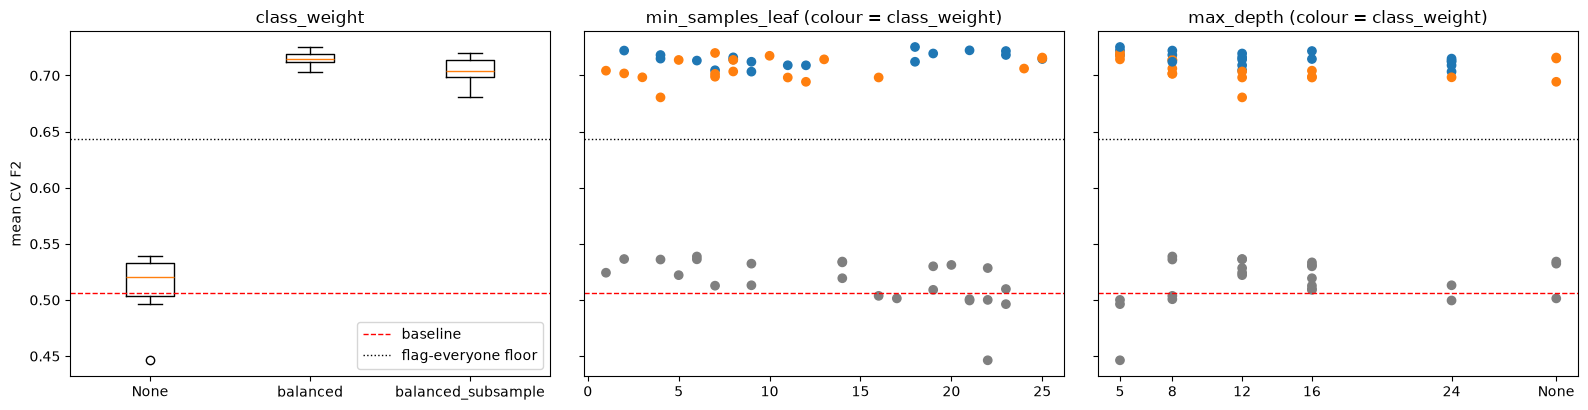

In [17]:
res_random = pd.DataFrame(random_search.cv_results_)
cw = as_label(res_random["param_clf__class_weight"])
depth = res_random["param_clf__max_depth"].astype(object).fillna(30).astype(float)  # plot None (unlimited) at 30
colors = cw.map({"None": "tab:gray", "balanced": "tab:blue", "balanced_subsample": "tab:orange"})

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
groups = ["None", "balanced", "balanced_subsample"]
axes[0].boxplot([res_random.loc[cw == g, "mean_test_score"] for g in groups], tick_labels=groups)
axes[0].set_title("class_weight")
axes[0].set_ylabel("mean CV F2")
axes[1].scatter(res_random["param_clf__min_samples_leaf"].astype(int), res_random["mean_test_score"], c=colors)
axes[1].set_title("min_samples_leaf (colour = class_weight)")
axes[2].scatter(depth, res_random["mean_test_score"], c=colors)
axes[2].set_xticks([5, 8, 12, 16, 24, 30], ["5", "8", "12", "16", "24", "None"])
axes[2].set_title("max_depth (colour = class_weight)")
for ax in axes:
    ax.axhline(baseline_cv.mean(), ls="--", c="red", lw=1, label="baseline")
    ax.axhline(floor_f2, ls=":", c="black", lw=1, label="flag-everyone floor")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

In [18]:
for p in ["class_weight", "max_features", "criterion", "max_depth"]:
    print(f"{p:>13}: {top_random[p].value_counts().to_dict()}")

 class_weight: {'balanced': 8, 'balanced_subsample': 2}
 max_features: {'sqrt': 4, '0.3': 2, '0.5': 2, 'log2': 2}
    criterion: {'entropy': 7, 'gini': 3}
    max_depth: {'5': 5, '8': 2, '12': 2, '16': 1}


<!-- phase:2b -->
**What the random search tells us:**
- **Re-weighting the classes is the biggest lever by far.** Every configuration with `class_weight=None` scores below the "flag everyone" floor, around the baseline. Every re-weighted configuration scores well above it. All of the top 10 re-weight, and 8 of 10 use `balanced`.
- **Shallow, regularised trees do best.** Half of the top 10 use `max_depth=5`, and most use large leaves. Their train scores (0.73–0.79) are close to their CV scores, so they aren't memorising the training data.
- **Several knobs barely matter.** `max_features` and `n_estimators` vary widely among the top 10, and `criterion` is split 7/3, yet all ten scores fall within 0.01 of each other.
- **The top 10 are separated by less than their own fold-to-fold noise.** They span 0.716–0.725, while each has a std of about 0.015–0.021. We'll come back to this in Phase 3.

### 2.4 Narrowing the space
We turn those observations into **explicit rules**, computed from `cv_results_` rather than picked by hand:
- **Categorical parameters:** keep every value used by at least 3 of the top 10, plus the winner's value.
- **Complexity integers** (`max_depth`, `min_samples_leaf`, `min_samples_split`): the winner's value ± one step.
- **`n_estimators`:** fixed at the winner's value. The top 10 range from 200 to 670 trees with the same score, so more trees don't improve F2. They only cost time.

In [19]:
best = random_search.best_params_
top10 = pd.DataFrame(random_search.cv_results_).sort_values("rank_test_score").head(10)


def frequent_values(param, min_count=3):
    """Values used by >= min_count of the random search's top 10, plus the winner's value."""
    counts = top10[f"param_{param}"].astype(object).value_counts()
    keep = [v for v, n in counts.items() if n >= min_count]
    if best[param] not in keep:
        keep.append(best[param])
    return [v.item() if hasattr(v, "item") else v for v in keep]


def neighbours(value, step, low):
    """value ± step, clipped at the parameter's lower bound."""
    return sorted({max(low, value - step), value, value + step})


param_grid = {
    "clf__class_weight": frequent_values("clf__class_weight"),
    "clf__criterion": frequent_values("clf__criterion"),
    "clf__max_features": frequent_values("clf__max_features"),
    "clf__max_depth": (neighbours(best["clf__max_depth"], step=1, low=1)
                       if best["clf__max_depth"] is not None else [16, 24, None]),
    "clf__min_samples_leaf": neighbours(best["clf__min_samples_leaf"], step=6, low=1),
    "clf__min_samples_split": neighbours(best["clf__min_samples_split"], step=10, low=2),
    "clf__n_estimators": [best["clf__n_estimators"]],
}
assert set(param_grid) <= set(pipe.get_params())

n_combos = int(np.prod([len(v) for v in param_grid.values()]))
print(f"{n_combos} combinations × {cv.get_n_splits()} folds = {n_combos * cv.get_n_splits()} fits\n")
param_grid

108 combinations × 5 folds = 540 fits



{'clf__class_weight': ['balanced'],
 'clf__criterion': ['entropy', 'gini'],
 'clf__max_features': ['sqrt', 0.3],
 'clf__max_depth': [4, 5, 6],
 'clf__min_samples_leaf': [12, 18, 24],
 'clf__min_samples_split': [16, 26, 36],
 'clf__n_estimators': [507]}

### 2.5 Focused search: `GridSearchCV`
Every combination in the narrowed region is tried, with the same scorer and folds, on the training split only. `refit=True` retrains the best configuration on all of `X_train`. We **never** refit `best_estimator_` ourselves.

In [20]:
grid_search = GridSearchCV(
    pipe,
    param_grid=param_grid,
    scoring=f2_scorer,
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
)
grid_search.fit(X_train, y_train)

summary = pd.DataFrame({
    "CV F2 (mean)": [baseline_cv.mean(), random_search.best_score_, grid_search.best_score_],
    "configs tried": [1, len(random_search.cv_results_["params"]), n_combos],
}, index=["Baseline (defaults)", "Random search best", "Grid search best"])
display(summary.round(3))
grid_search.best_params_

,CV F2 (mean),configs tried
Baseline (defaults),0.506,1
Random search best,0.725,60
Grid search best,0.726,108


{'clf__class_weight': 'balanced',
 'clf__criterion': 'entropy',
 'clf__max_depth': 5,
 'clf__max_features': 0.3,
 'clf__min_samples_leaf': 24,
 'clf__min_samples_split': 16,
 'clf__n_estimators': 507}

In [21]:
top_grid = top_candidates(grid_search)
top_grid.round(3)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,class_weight,criterion,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators
0,1,0.726,0.019,0.742,balanced,entropy,5,0.3,24,16,507
1,1,0.726,0.019,0.742,balanced,entropy,5,0.3,24,26,507
2,1,0.726,0.019,0.742,balanced,entropy,5,0.3,24,36,507
3,4,0.726,0.018,0.743,balanced,gini,5,0.3,24,16,507
4,4,0.726,0.018,0.743,balanced,gini,5,0.3,24,26,507
5,4,0.726,0.018,0.743,balanced,gini,5,0.3,24,36,507
6,7,0.726,0.020,0.746,balanced,gini,6,sqrt,18,26,507
7,7,0.726,0.020,0.746,balanced,gini,6,sqrt,18,36,507
8,7,0.726,0.020,0.746,balanced,gini,6,sqrt,18,16,507
9,10,0.725,0.017,0.748,balanced,entropy,6,sqrt,12,16,507


Two details to check before trusting the grid:

- **Identical triplets.** Candidates come in groups of three with identical scores, differing only in `min_samples_split`. When `min_samples_leaf` ≥ 18, a node needs at least 36 samples to split into two valid leaves, so a `min_samples_split` of 16, 26 or 36 never applies. In that region the grid explored fewer *distinct* models than its 108 combinations suggest. Sklearn breaks ties in favour of the first candidate, which behaves identically to the other two.
- **The winner is at the edge of the grid.** The best `min_samples_leaf` (24) is the largest value we tried, which would normally be a reason to extend the grid. Below is the best CV F2 for each value of each parameter. If the curve is flat compared with the fold std, extending the grid would chase noise rather than signal.

In [22]:
res_grid = pd.DataFrame(grid_search.cv_results_)
for p, values in param_grid.items():
    if len(values) > 1:
        best_per_value = res_grid.groupby(as_label(res_grid[f"param_{p}"]))["mean_test_score"].max()
        print(f"{p.removeprefix('clf__'):>17}: {best_per_value.round(4).to_dict()}")
print(f"\nTypical fold std of the top candidates: {top_grid['std_test_score'].mean():.4f}")

        criterion: {'entropy': 0.726, 'gini': 0.7258}
     max_features: {'0.3': 0.726, 'sqrt': 0.7257}
        max_depth: {'4': 0.7219, '5': 0.726, '6': 0.7257}
 min_samples_leaf: {'12': 0.7254, '18': 0.7257, '24': 0.726}
min_samples_split: {'16': 0.726, '26': 0.726, '36': 0.726}

Typical fold std of the top candidates: 0.0189


**Reading the grid:**
- **The edge isn't hiding a better region.** Across `min_samples_leaf` = 12 → 18 → 24, the best score moves by only 0.0006 (0.7254 → 0.7260), about **30× smaller than the fold std** (~0.019).
- **`max_depth` has a real optimum inside the grid.** Depth 4 is clearly worse (0.722), while 5 and 6 are equivalent.
- **`min_samples_split` has no effect here at all**, which matches the identical triplets above.
- **The grid confirms what the random search found.** Its best CV F2 (0.726) is barely above the random search's (0.725). That's expected: the coarse search had already done most of the work, and the grid's job was to check the neighbourhood carefully.

The top grid candidates again sit **within a few thousandths** of each other. Choosing among them by their mean score alone would mean choosing on noise. Phase 3 therefore looks at how much each candidate's score moves across folds before choosing.

<!-- phase:3 -->
## Phase 3: Selecting the final model

### 3.1 How much does each candidate move across folds?
A mean CV score is an average of 5 fold scores. Two candidates with the same mean can behave very differently: one scores steadily, the other swings between good and bad folds. For each **distinct** top candidate we look at:
- its mean and std across folds
- its **worst fold**, the downside if the model meets an unlucky slice of customers
- its **train–CV gap**, where a large gap means the model is memorising the training data

The identical triplets from Phase 2 are the same model, so we keep one row each, the one sklearn would pick.

In [23]:
N_FOLDS = cv.get_n_splits()
split_cols = [f"split{i}_test_score" for i in range(N_FOLDS)]

distinct = (res_grid.sort_values("rank_test_score", kind="stable")
            .drop_duplicates(subset=split_cols))  # identical fold scores = identical model

stab = distinct.head(10).assign(
    worst_fold=lambda d: d[split_cols].min(axis=1),
    train_cv_gap=lambda d: d["mean_train_score"] - d["mean_test_score"],
)
param_cols = [c for c in stab.columns if c.startswith("param_")]
stability_table = stab[["rank_test_score", "mean_test_score", "std_test_score", "worst_fold",
                        "train_cv_gap", *split_cols, *param_cols]].copy()
stability_table[param_cols] = stability_table[param_cols].apply(as_label)
stability_table.columns = [c.replace("param_clf__", "").replace("_test_score", "") for c in stability_table.columns]
stability_table.round(4)

,rank,mean,std,worst_fold,train_cv_gap,split0,split1,split2,split3,split4,class_weight,criterion,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators
33,1,0.7260,0.0191,0.6928,0.0163,0.7220,0.6928,0.7290,0.7504,0.7356,balanced,entropy,5,0.3,24,16,507
87,4,0.7258,0.0185,0.6936,0.0175,0.7220,0.6936,0.7290,0.7496,0.7347,balanced,gini,5,0.3,24,16,507
93,7,0.7257,0.0200,0.7044,0.0200,0.7280,0.7044,0.7113,0.7622,0.7226,balanced,gini,6,sqrt,18,16,507
36,10,0.7254,0.0167,0.7074,0.0221,0.7254,0.7074,0.7117,0.7552,0.7274,balanced,entropy,6,sqrt,12,16,507
91,11,0.7254,0.0202,0.6975,0.0238,0.7289,0.6975,0.7143,0.7590,0.7274,balanced,gini,6,sqrt,12,26,507
84,12,0.7254,0.0153,0.6966,0.0187,0.7258,0.6966,0.7295,0.7412,0.7339,balanced,gini,5,0.3,18,16,507
92,15,0.7248,0.0183,0.7040,0.0227,0.7259,0.7040,0.7117,0.7574,0.7252,balanced,gini,6,sqrt,12,36,507
100,16,0.7242,0.0150,0.6965,0.0321,0.7255,0.6965,0.7249,0.7413,0.7326,balanced,gini,6,0.3,12,26,507
90,17,0.7242,0.0163,0.7022,0.0249,0.7263,0.7022,0.7139,0.7510,0.7274,balanced,gini,6,sqrt,12,16,507
29,18,0.7242,0.0174,0.6927,0.0188,0.7228,0.6927,0.7282,0.7454,0.7317,balanced,entropy,5,0.3,12,36,507


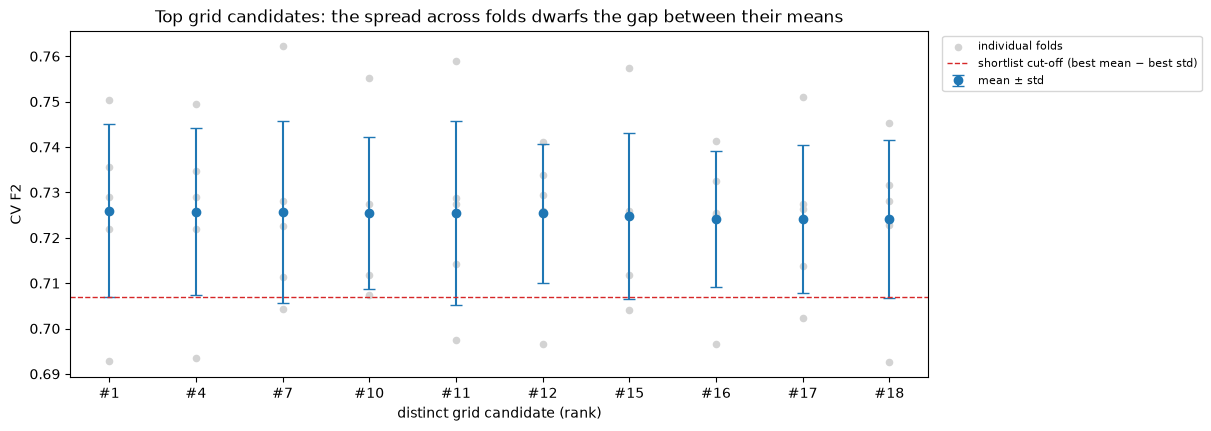

In [24]:
best_mean = res_grid.loc[grid_search.best_index_, "mean_test_score"]
best_std = res_grid.loc[grid_search.best_index_, "std_test_score"]
cutoff = best_mean - best_std

x = np.arange(len(stab))
fig, ax = plt.subplots(figsize=(12, 4.2), layout="constrained")
for i, (_, row) in enumerate(stab.iterrows()):
    ax.scatter([i] * N_FOLDS, row[split_cols], color="lightgray", s=20, zorder=1,
               label="individual folds" if i == 0 else None)
ax.errorbar(x, stab["mean_test_score"], yerr=stab["std_test_score"], fmt="o", capsize=4,
            color="tab:blue", zorder=2, label="mean ± std")
ax.axhline(cutoff, ls="--", c="tab:red", lw=1, label="shortlist cut-off (best mean − best std)")
ax.set_xticks(x, [f"#{r}" for r in stab["rank_test_score"]])
ax.set_xlabel("distinct grid candidate (rank)")
ax.set_ylabel("CV F2")
ax.set_title("Top grid candidates: the spread across folds dwarfs the gap between their means")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.show()

### 3.2 The selection rule
The rule was set in the project plan before any search ran: *among candidates statistically tied on the mean, prefer the more stable one*. Here we make it precise:

1. **Shortlist** every candidate whose mean CV F2 is within **one std** of the best mean. Sklearn's own [refit-callable example](https://scikit-learn.org/stable/auto_examples/model_selection/plot_grid_search_refit_callable.html) uses the same cut-off. Inside it, the differences in mean are noise.
2. A shortlisted candidate replaces the top-ranked one only if it is **meaningfully** steadier. Its fold std has to be lower by more than the uncertainty of a std measured on only 5 folds, which is ≈ std / √(2·(k−1)). A std estimated from five numbers is itself noisy, so we don't reward tiny differences.
3. Otherwise we keep the top-ranked candidate, which `refit=True` has already retrained.

The rule is written as a function. If it ever picks a different candidate, we hand it to `GridSearchCV(refit=select_index)`, so sklearn still does the retraining and we never refit by hand.

In [25]:
def select_index(cv_results):
    """Index of the chosen candidate: top-ranked, unless a statistically tied one is meaningfully steadier."""
    res = pd.DataFrame(cv_results)
    top = int(res["rank_test_score"].idxmin())  # same tie-break as sklearn's best_index_
    top_mean, top_std = res.loc[top, ["mean_test_score", "std_test_score"]]
    std_noise = top_std / np.sqrt(2 * (len([k for k in res if k.startswith("split") and k.endswith("_test_score")]) - 1))
    shortlist = res[res["mean_test_score"] >= top_mean - top_std]
    steadier = shortlist[shortlist["std_test_score"] < top_std - std_noise]
    return top if steadier.empty else int(steadier["mean_test_score"].idxmax())


std_noise = best_std / np.sqrt(2 * (N_FOLDS - 1))
shortlist = distinct[distinct["mean_test_score"] >= cutoff]
print(f"Best mean CV F2: {best_mean:.4f}  (std {best_std:.4f})")
print(f"Shortlist cut-off: {cutoff:.4f} -> {len(shortlist)} of {len(distinct)} distinct candidates are statistically tied")
print(f"Noise in a {N_FOLDS}-fold std: ±{std_noise:.4f} -> a challenger needs std < {best_std - std_noise:.4f}")
print(f"Lowest std in the shortlist: {shortlist['std_test_score'].min():.4f}")

chosen = select_index(grid_search.cv_results_)
print(f"\nChosen candidate index: {chosen}  |  grid_search.best_index_: {grid_search.best_index_}")

Best mean CV F2: 0.7260  (std 0.0191)
Shortlist cut-off: 0.7069 -> 60 of 60 distinct candidates are statistically tied
Noise in a 5-fold std: ±0.0067 -> a challenger needs std < 0.0123
Lowest std in the shortlist: 0.0147

Chosen candidate index: 33  |  grid_search.best_index_: 33


In [26]:
if chosen == grid_search.best_index_:
    final_search = grid_search  # refit=True already retrained this candidate on all of X_train
else:
    # A steadier candidate won: let sklearn refit it through a callable. Never refit by hand.
    final_search = GridSearchCV(pipe, param_grid=param_grid, scoring=f2_scorer, cv=cv, n_jobs=-1,
                                refit=select_index, return_train_score=True).fit(X_train, y_train)

final_model = final_search.best_estimator_
final_idx = final_search.best_index_
final_cv_mean = final_search.cv_results_["mean_test_score"][final_idx]
final_cv_std = final_search.cv_results_["std_test_score"][final_idx]
final_params = {k.removeprefix("clf__"): v for k, v in final_search.cv_results_["params"][final_idx].items()}

print(f"Final model CV F2: {final_cv_mean:.3f} ± {final_cv_std:.3f}")
final_params

Final model CV F2: 0.726 ± 0.019


{'class_weight': 'balanced',
 'criterion': 'entropy',
 'max_depth': 5,
 'max_features': 0.3,
 'min_samples_leaf': 24,
 'min_samples_split': 16,
 'n_estimators': 507}

**Why this model?** The rule keeps the grid's top-ranked candidate. Its mean being the highest is *not* the reason:
- **The mean doesn't separate the candidates.** All 60 distinct grid candidates are inside the shortlist. The top 10 means span only 0.7242–0.7260, a small fraction of one fold std (~0.019).
- **Stability doesn't separate them either.** The steadiest candidate in the shortlist has a std of 0.0147. That's lower than our winner's 0.0191, but not by more than the ±0.0067 noise in a 5-fold std, so it isn't a real stability advantage.
- **What tips it is simplicity.** The chosen model has the **smallest train–CV gap in the top 10** (0.016). It is the most regularised, with the shallowest trees (`max_depth=5`) and the largest leaves (`min_samples_leaf=24`), so it is the least likely to have learned quirks of the training data. Candidate #4 is the same configuration with `gini` instead of `entropy`, and it is indistinguishable.
- **The trade-off we accepted.** Its worst fold (0.693) is among the lowest of the top 10. Candidate #10 has a better worst fold (0.707) and a lower std (0.0167), but it uses deeper trees with smaller leaves (depth 6, leaf 12) and a larger gap (0.022). With differences this small, either choice is defensible; we prefer the simpler model.

### 3.3 The final test-set evaluation
This is the **second and last** time the test set is used. We report the same metrics, from the same `evaluate()` helper, that we reported for the baseline.

In [27]:
final_metrics, final_cm = evaluate(final_model, "Tuned (grid search)")  # test set use #2

[test set use 2/2] Tuned (grid search)


,Tuned (grid search)
F2,0.720
Recall,0.805
Precision,0.507
F1,0.622
ROC-AUC,0.843
Accuracy,0.740


,Pred: stays,Pred: churns
Actual: stays,742,293
Actual: churns,73,301


### 3.4 Baseline vs. tuned

In [28]:
comparison = pd.concat([baseline_metrics, final_metrics], axis=1)
comparison["Change"] = comparison.iloc[:, 1] - comparison.iloc[:, 0]
display(comparison.round(3))

cv_compare = pd.DataFrame({
    "CV F2 mean": [baseline_cv.mean(), final_cv_mean],
    "CV F2 std": [baseline_cv.std(), final_cv_std],
}, index=["Baseline (defaults)", "Tuned (grid search)"])
display(cv_compare.round(3))

n_churners = int(final_cm.loc["Actual: churns"].sum())  # counted from the confusion matrix
for name, cm in [("Baseline", baseline_cm), ("Tuned", final_cm)]:
    caught, missed = cm.loc["Actual: churns", "Pred: churns"], cm.loc["Actual: churns", "Pred: stays"]
    false_alarms = cm.loc["Actual: stays", "Pred: churns"]
    print(f"{name:>8}: catches {caught}/{n_churners} churners, misses {missed}, "
          f"sends {false_alarms} unneeded retention offers")

assert TEST_SET_USES == 2, "The test set must be used exactly twice"
print(f"\nTest set used {TEST_SET_USES} times in total: baseline + final model.")

,Baseline (defaults),Tuned (grid search),Change
F2,0.498,0.720,0.222
Recall,0.476,0.805,0.329
Precision,0.610,0.507,-0.103
F1,0.535,0.622,0.087
ROC-AUC,0.817,0.843,0.027
Accuracy,0.780,0.740,-0.040


,CV F2 mean,CV F2 std
Baseline (defaults),0.506,0.024
Tuned (grid search),0.726,0.019


Baseline: catches 178/374 churners, misses 196, sends 114 unneeded retention offers
   Tuned: catches 301/374 churners, misses 73, sends 293 unneeded retention offers

Test set used 2 times in total: baseline + final model.


### Bottom line for StreamLoop
- **Missed churners drop from 196 to 73** out of 374 (recall 0.476 → 0.805). That's 123 more at-risk customers who can get a retention offer in time.
- **The price is 179 more unneeded offers** (114 → 293), so precision falls from 0.61 to 0.51. The brief says a missed churner costs far more than an unneeded offer, so this is the trade we were aiming for. Accuracy falls (0.780 → 0.740) for the same reason, which is exactly why accuracy wasn't our target.
- **The model also got better at ranking customers.** ROC-AUC, which doesn't depend on the decision threshold, rises from 0.817 to 0.843. So the improvement isn't just a shift towards flagging more people.
- **The CV estimate held up.** The tuned model's CV F2 of 0.726 ± 0.019 predicted a test F2 of 0.720 well within one fold std. The search didn't overfit its own validation folds, and the model clears the 0.644 "flag everyone" floor by a clear margin.

**Next steps** (deliberately not done here, to keep the test set clean):
- Tune the **decision threshold** (currently 0.5) on out-of-fold predictions from the training split, for example with sklearn's `TunedThresholdClassifierCV`. Never tune it on the test set.
- Once finance can put numbers on *the cost of a lost customer* and *the cost of a retention offer*, replace F2 with an explicit **cost-based metric**.
- Before a production decision, use **repeated CV** (for example 5×5 folds) on the shortlisted candidates to tighten the stability estimates.